# When is a second chest X-ray view worth acquiring? — V4

**Complete Kaggle research pipeline · full training defaults · three fine-tuning seeds**

Import this notebook, attach the two datasets below, enable **GPU + Internet**, and Run All.

1. [CheXpert-small — ashery/chexpert](https://www.kaggle.com/datasets/ashery/chexpert)
2. [Indiana University — raddar/chest-xrays-indiana-university](https://www.kaggle.com/datasets/raddar/chest-xrays-indiana-university)

**No new Kaggle dataset is required.** Keep the full CheXpert-small input, not a subset. The official PadChest Kaggle sample is too small for our intended external validation. Optional full PadChest support is configured below; MIMIC is deferred until access is granted.

V4 preserves the v3 patient partitions and tests second-view value against four stronger frontal alternatives. It adds a candidate conditional score-CDF selector, direct-gain and benefit/harm baselines, repeated shuffled-view controls, paired intervals, and two-sided risk analysis.

**Research integrity:** previously inspected CheXpert/IU results remain exploratory. A completed notebook or favorable result does not establish novelty or submission readiness. Source risk calculations are explicitly nominal after data reuse. No result is labeled clinically certified.

**Runtime:** five predictor variants × three seeds, up to 12 epochs. One GPU is used. This may require multiple Kaggle sessions. A default 10-hour training budget pauses at a checkpoint boundary. Preserve full Kaggle Output to resume; read the instructions below.


In [1]:
# Environment setup: keep Kaggle's installed Torch/torchvision pair.
# Do not pip-upgrade Torch inside the notebook.
import os, sys
from pathlib import Path
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('MKL_NUM_THREADS', '4')
import torch, torchvision, numpy, pandas, sklearn, scipy
print('Torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NOT ENABLED')
if not torch.cuda.is_available():
    raise RuntimeError('Enable a GPU in Kaggle Settings, then Run All.')
Path('/kaggle/working').mkdir(parents=True, exist_ok=True)


Torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
GPU: Tesla T4


## Complete pipeline source

The next cell writes the included module into the writable Kaggle workspace. No GitHub repository, private package or separate code input is required. You can inspect every function here. Change routine settings in the configuration cell rather than editing this source; content hashes protect resumed runs.


In [2]:
%%writefile /kaggle/working/v4_pipeline.py
"""V4: residual value of a second chest X-ray view.

Research pipeline, not clinical software. Run the companion Kaggle notebook.
The fixed v3 patient manifest is supplied alongside this module.
"""
from __future__ import annotations

import ast
import copy
import gc
import hashlib
import html
import io
import json
import math
import os
import platform
import random
import re
import shutil
import sys
import time
import zipfile
from dataclasses import asdict, dataclass
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from scipy.optimize import minimize
from scipy.special import expit, logit
from scipy.stats import norm
from scipy.stats import beta as beta_distribution
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

LABELS = ["Pleural Effusion", "Cardiomegaly", "Atelectasis"]
VARIANTS = ["frontal", "paired", "frontal_twice", "distilled", "frontal_extra"]
CHEAP_VARIANTS = ["frontal", "frontal_twice", "distilled", "frontal_extra"]


@dataclass
class Config:
    version: str = "4.0.0"
    input_root: str = "/kaggle/input"
    output_root: str = "/kaggle/working/second_view_v4"
    manifest_path: str = "/kaggle/working/v3_patient_manifest.csv"
    chexpert_root: str | None = None
    iu_root: str | None = None
    # Optional official full PadChest inputs. Never required for the default run.
    padchest_csv: str | None = None
    padchest_image_root: str | None = None
    padchest_compute_authorized: bool = False
    local_imagenet_weights: str | None = None
    resume_root: str | None = None
    seeds: tuple = (42, 123, 2026)
    split_seed: int = 731
    image_size: int = 320
    batch_size: int = 12
    accumulation_steps: int = 2
    workers: int = 2
    epochs: int = 12
    min_epochs: int = 5
    patience: int = 4
    encoder_lr: float = 3e-5
    head_lr: float = 3e-4
    weight_decay: float = 1e-4
    dropout: float = .2
    distill_weight: float = .35
    distill_temperature: float = 2.
    amp: bool = True
    pca_components: int = 24
    gate_iterations: int = 150
    gate_min_leaf: int = 40
    gate_l2: float = 10.
    quantiles: tuple = (.05, .1, .2, .3, .4, .5, .6, .7, .8, .9, .95)
    costs: tuple = (1., 3., 5.)
    primary_cost: float = 3.
    budgets: tuple = (0., .1, .25, .5, .75, 1.)
    primary_budget: float = .25
    acquisition_prices: tuple = (0., .0025, .005, .01, .02)
    # Normalized average loss, NOT percentages of harmed patients.
    risk_alpha: float = .02
    risk_beta: float = .02
    risk_delta: float = .05
    risk_tolerances: tuple = (.01, .02, .05, .10)
    risk_etas: tuple = (.5, 1., 2., 4.)
    risk_grid_quantiles: tuple = (0., .1, .25, .5, .75, .9, 1.)
    bootstrap_reps: int = 3000
    shuffle_repeats: int = 5
    sample_fractions: tuple = (.25, .5, 1.)
    sample_repeats: int = 2
    calibration_min_class: int = 20
    strict_iu: bool = True
    # Graceful epoch-boundary pause; resume from saved Kaggle Output.
    session_hours: float = 10.
    require_cuda: bool = True


def json_default(x):
    if isinstance(x, (np.integer, np.floating, np.bool_)):
        return x.item()
    if isinstance(x, (Path,)):
        return str(x)
    if isinstance(x, np.ndarray):
        return x.tolist()
    raise TypeError(type(x).__name__)


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, default=json_default, allow_nan=False))
    os.replace(tmp, path)


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def atomic_npz(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    with tmp.open("wb") as f:
        np.savez_compressed(f, **arrays)
    os.replace(tmp, path)


def read_npz(path):
    with np.load(path, allow_pickle=False) as f:
        return {k: f[k] for k in f.files}


def split_frame(frame, fraction, seed):
    a, b = train_test_split(frame, test_size=fraction, random_state=seed)
    return a.reset_index(drop=True), b.reset_index(drop=True)


def find_csv(root, filename, required):
    hits = []
    for p in Path(root).rglob(filename):
        try:
            if set(required) <= set(pd.read_csv(p, nrows=0).columns):
                hits.append(p)
        except (ValueError, OSError, pd.errors.ParserError):
            pass
    if len(hits) != 1:
        raise RuntimeError(f"Expected one {filename} under {root}; found {hits}. Set an explicit dataset root.")
    return hits[0]


class Resolver:
    def __init__(self, root):
        self.root = Path(root)
        self.index = None

    def resolve(self, raw):
        pieces = str(raw).replace("\\", "/").lstrip("/").split("/")
        for root in [self.root, self.root.parent]:
            for drop in range(len(pieces)):
                p = root.joinpath(*pieces[drop:])
                if p.is_file():
                    return str(p)
        if self.index is None:
            self.index = {}
            for p in self.root.rglob("*"):
                if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                    self.index.setdefault(p.name, []).append(str(p))
        hits = self.index.get(pieces[-1], [])
        if len(hits) == 1:
            return hits[0]
        raise FileNotFoundError(f"Missing/ambiguous image {raw} under {self.root}. Attach the complete paired dataset.")


def check_images(frame, seen=None, strict=False):
    seen = set() if seen is None else set(seen)
    kept, rejected = [], []
    for i, row in frame.iterrows():
        try:
            hs = []
            for view in ["frontal", "lateral"]:
                with Image.open(row[view]) as im:
                    im.verify()
                hs.append(sha256(row[view]))
            if hs[0] == hs[1] or any(h in seen for h in hs):
                raise ValueError("exact duplicate image within/across cohorts")
            seen.update(hs)
            kept.append(dict(row, frontal_sha256=hs[0], lateral_sha256=hs[1]))
        except (OSError, ValueError) as e:
            rejected.append({"study_id": row.study_id, "reason": str(e)})
    if strict and rejected:
        raise RuntimeError(f"Original v3 source cohort changed: {len(rejected)} invalid pairs, e.g. {rejected[:3]}")
    return pd.DataFrame(kept), seen, rejected


def load_source(cfg, out):
    csv = find_csv(cfg.chexpert_root or cfg.input_root, "train.csv", ["Path", "Frontal/Lateral"] + LABELS)
    raw = pd.read_csv(csv)
    raw["key"] = raw.Path.astype(str).str.replace(r"^.*?/train/", "train/", regex=True)
    if raw.key.duplicated().any():
        raise ValueError("Duplicate image paths in CheXpert metadata")
    raw = raw.set_index("key")
    source = pd.read_csv(cfg.manifest_path)
    if source.patient_id.duplicated().any() or set(source.v3_split) != {"base", "gate", "dev", "cert", "test"}:
        raise ValueError("Invalid frozen v3 manifest")
    resolver = Resolver(csv.parent)
    for i, row in source.iterrows():
        for view in ["frontal", "lateral"]:
            key = row[view]
            if key not in raw.index:
                raise ValueError(f"Original v3 image missing from current metadata: {key}")
            r = raw.loc[key]
            if str(r["Frontal/Lateral"]).lower() != view:
                raise ValueError(f"View mismatch: {key}")
            for j, label in enumerate(LABELS):
                val = pd.to_numeric(r[label], errors="coerce")
                known = val in (0, 1)
                if known != bool(row[f"m{j}"]) or (known and val != row[f"y{j}"]):
                    raise ValueError(f"Labels differ from v3: {key} / {label}; investigate dataset version")
            source.loc[i, view] = resolver.resolve(key)
    source, seen, _ = check_images(source, strict=True)
    source.to_csv(out / "source_manifest.csv", index=False)
    base = source[source.v3_split == "base"].reset_index(drop=True)
    fit, stop = split_frame(base, .15, cfg.split_seed + 10)
    dev = source[source.v3_split == "dev"].reset_index(drop=True)
    probcal, policydev = split_frame(dev, .5, cfg.split_seed + 11)
    splits = {"fit": fit, "stop": stop, "probcal": probcal, "policydev": policydev}
    for old, new in [("gate", "gate"), ("cert", "riskcal"), ("test", "test")]:
        splits[new] = source[source.v3_split == old].reset_index(drop=True)
    # More-frontal-data control: match the paired model's images per epoch using
    # additional patients outside EVERY original paired cohort partition.
    extra = raw.reset_index()
    extra["patient_id"] = extra.key.str.extract(r"(patient\d+)")[0]
    extra = extra[(extra["Frontal/Lateral"].str.lower() == "frontal") &
                  ~extra.patient_id.isin(source.patient_id) & extra[LABELS[0]].isin([0, 1])].copy()
    extra["is_pa"] = extra.get("AP/PA", pd.Series("", index=extra.index)).eq("PA")
    extra = extra.sort_values(["patient_id", "is_pa", "key"], ascending=[True, False, True]).drop_duplicates("patient_id")
    extra = extra.sample(frac=1, random_state=cfg.split_seed + 12)
    extra_rows = []
    for _, r in extra.iterrows():
        if len(extra_rows) >= len(fit):
            break
        try:
            path = resolver.resolve(r.key)
            with Image.open(path) as im:
                im.verify()
            h = sha256(path)
            if h in seen:
                continue
            seen.add(h)
            row = dict(patient_id=r.patient_id, study_id="/".join(r.key.split("/")[1:3]),
                       frontal=path, lateral=path, source="chexpert_extra_frontal", frontal_sha256=h,
                       lateral_sha256="not_acquired", v3_split="unused_patient")
            for j, label in enumerate(LABELS):
                val = pd.to_numeric(r[label], errors="coerce")
                row[f"m{j}"] = val in (0, 1)
                row[f"y{j}"] = float(val) if val in (0, 1) else 0.
            extra_rows.append(row)
        except (OSError, ValueError):
            continue
    if len(extra_rows) < len(fit):
        raise ValueError(f"Need {len(fit)} additional frontal patients for the matched-image-count control; resolved {len(extra_rows)}. Attach full CheXpert-small, not a subset.")
    splits["extra_frontal"] = pd.DataFrame(extra_rows)
    for name, frame in splits.items():
        counts = frame.y0.value_counts()
        if min(counts.get(0, 0), counts.get(1, 0)) < cfg.calibration_min_class:
            raise ValueError(f"Too few primary classes in {name}: {counts.to_dict()}")
    return splits, seen, sha256(csv)


NEG = {
    "Pleural Effusion": [r"\bno (?:evidence of )?(?:pleural )?effusions?\b", r"\bwithout (?:a )?(?:pleural )?effusions?\b", r"\bnegative for (?:pleural )?effusions?\b", r"\bno pneumothorax or (?:pleural )?effusions?\b", r"\bno (?:pleural )?effusions? or pneumothorax\b"],
    "Cardiomegaly": [r"\bno cardiomegaly\b", r"\bheart (?:size|and mediastinal contours) (?:is |are )?(?:within normal limits|normal)\b", r"\bcardiac silhouette (?:is )?(?:normal|within normal limits)\b"],
    "Atelectasis": [r"\bno (?:evidence of )?atelectasis\b", r"\bwithout atelectasis\b"],
}
MESH = {"Pleural Effusion": {"pleural effusion"}, "Cardiomegaly": {"cardiomegaly"}, "Atelectasis": {"atelectasis", "pulmonary atelectasis"}}


def iu_label(row, label):
    terms = {s.strip().split("/")[0] for s in str(row.get("MeSH", row.get("mesh", ""))).lower().split(";")}
    pos = bool(terms & MESH[label])
    report = " ".join(str(row.get(c, "")) for c in ["findings", "impression"]).lower()
    normal = bool(re.search(r"^(?:normal chest\.?|normal chest radiograph\.?|normal study\.?)$", str(row.get("impression", "")).lower().strip())) or terms == {"normal"}
    neg = normal or any(re.search(p, report) for p in NEG[label])
    if pos and not neg:
        return 1., True
    if neg and not pos:
        return 0., True
    return 0., False


def load_iu(cfg, seen, out):
    try:
        p = find_csv(cfg.iu_root or cfg.input_root, "indiana_projections.csv", ["uid", "filename", "projection"])
    except RuntimeError:
        if cfg.strict_iu:
            raise
        return pd.DataFrame(), seen
    r = find_csv(p.parent, "indiana_reports.csv", ["uid"])
    reports = pd.read_csv(r).fillna("")
    reports.uid = reports.uid.astype(str)
    if reports.uid.duplicated().any():
        raise ValueError("Duplicate IU report IDs")
    reports = reports.set_index("uid")
    proj = pd.read_csv(p)
    proj.uid = proj.uid.astype(str)
    resolver = Resolver(p.parent)
    rows, rejected = [], []
    for uid, group in proj.groupby("uid", sort=True):
        f = group[group.projection.str.lower() == "frontal"].sort_values("filename")
        l = group[group.projection.str.lower() == "lateral"].sort_values("filename")
        if f.empty or l.empty or uid not in reports.index:
            continue
        row = {"patient_id": f"IU-study-{uid}", "study_id": f"IU-{uid}", "source": "iu", "identity_unit": "study_not_verified_patient"}
        for j, lab in enumerate(LABELS):
            row[f"y{j}"], row[f"m{j}"] = iu_label(reports.loc[uid], lab)
        if not row["m0"]:
            continue
        try:
            row.update(frontal=resolver.resolve(f.iloc[0].filename), lateral=resolver.resolve(l.iloc[0].filename))
            rows.append(row)
        except FileNotFoundError as e:
            rejected.append({"study_id": uid, "reason": str(e)})
    if not rows:
        raise ValueError("No IU pairs with known primary label")
    frame, seen, invalid = check_images(pd.DataFrame(rows), seen)
    pd.DataFrame(rejected + invalid, columns=["study_id", "reason"]).to_csv(out / "iu_exclusions.csv", index=False)
    return frame, seen


def pad_labels(value):
    try:
        labels = ast.literal_eval(str(value))
    except (SyntaxError, ValueError):
        return None
    if not isinstance(labels, list) or not all(isinstance(x, str) for x in labels):
        return None
    return {x.lower().strip() for x in labels}


def load_padchest(cfg, seen, out):
    if cfg.padchest_csv is None:
        return {}
    if not cfg.padchest_image_root or not cfg.padchest_compute_authorized:
        raise ValueError("Full PadChest needs its image root and confirmation that its terms permit this compute location.")
    raw = pd.read_csv(cfg.padchest_csv, low_memory=False)
    required = {"PatientID", "StudyID", "ImageID", "Projection", "Labels"}
    if not required <= set(raw):
        raise ValueError(f"PadChest metadata missing {required - set(raw)}")
    resolver = Resolver(cfg.padchest_image_root)
    rows, rejected = [], []
    for (pid, sid), group in raw.groupby(["PatientID", "StudyID"], sort=True):
        f = group[group.Projection.astype(str).str.upper().isin(["PA", "AP", "AP_HORIZONTAL"])].sort_values("ImageID")
        l = group[group.Projection.astype(str).str.upper().isin(["L", "LATERAL"])].sort_values("ImageID")
        if f.empty or l.empty:
            continue
        pa = f[f.Projection.astype(str).str.upper() == "PA"]
        if not pa.empty:
            f = pa
        fl, ll = pad_labels(f.iloc[0].Labels), pad_labels(l.iloc[0].Labels)
        if fl is None or ll is None or fl != ll or {"exclude", "suboptimal study"} & fl:
            continue
        # Conservative positive/explicit-normal mapping, not unmentioned=negative.
        row = {"patient_id": f"pad-{pid}", "study_id": f"pad-{sid}", "source": "padchest", "identity_unit": "patient", "label_method": str(f.iloc[0].get("MethodLabel", "unknown"))}
        for j, term in enumerate(["pleural effusion", "cardiomegaly", "atelectasis"]):
            pos, neg = term in fl, "normal" in fl
            row[f"y{j}"] = float(pos and not neg)
            row[f"m{j}"] = bool(pos != neg)
        if not row["m0"]:
            continue
        try:
            row.update(frontal=resolver.resolve(f.iloc[0].ImageID), lateral=resolver.resolve(l.iloc[0].ImageID))
            rows.append(row)
        except FileNotFoundError as e:
            rejected.append({"study_id": sid, "reason": str(e)})
    if not rows:
        raise ValueError("No eligible full PadChest pairs. The small Kaggle sample is not suitable.")
    frame = pd.DataFrame(rows).sort_values(["patient_id", "study_id"]).drop_duplicates("patient_id")
    frame, _, invalid = check_images(frame, seen)
    pd.DataFrame(rejected + invalid, columns=["study_id", "reason"]).to_csv(out / "padchest_exclusions.csv", index=False)
    if len(frame) < 1000:
        raise ValueError(f"Only {len(frame)} PadChest pairs. Supply a full paired cohort; do not use the small sample as confirmatory evidence.")
    cal, test = split_frame(frame, .6, cfg.split_seed + 90)
    prob, risk = split_frame(cal, .5, cfg.split_seed + 91)
    return {"pad_probcal": prob, "pad_riskcal": risk, "pad_test": test}


def audit_splits(splits, out):
    rows = []
    for name, frame in splits.items():
        if frame.patient_id.duplicated().any():
            raise ValueError(f"Duplicate identities in {name}")
        frame.to_csv(out / f"cohort_{name}.csv", index=False)
        for other, f2 in splits.items():
            if name != other and set(frame.patient_id) & set(f2.patient_id):
                raise AssertionError(f"Patient leakage between {name} and {other}")
        for j, label in enumerate(LABELS):
            m = frame[f"m{j}"].to_numpy(bool)
            y = frame[f"y{j}"].to_numpy()
            rows.append(dict(split=name, label=label, n=len(frame), positives=int(((y == 1) & m).sum()), negatives=int(((y == 0) & m).sum()), unknown=int((~m).sum())))
    pd.DataFrame(rows).to_csv(out / "cohort_counts.csv", index=False)
    return rows


def decision_loss(y, p, w):
    a = np.asarray(p) >= 1. / (1. + w)
    y = np.asarray(y)
    return np.where((y == 1) & ~a, w, np.where((y == 0) & a, 1., 0.))


def gain_parts(y, p0, p1, w):
    l0, l1 = decision_loss(y, p0, w), decision_loss(y, p1, w)
    g = (l0 - l1) / max(w, 1.)
    return l0, l1, np.maximum(g, 0), np.maximum(-g, 0)


class Platt:
    """Positive-slope sigmoid, fitted on a dedicated probability-calibration split."""
    def fit(self, scores, y, minimum=20):
        scores, y = np.asarray(scores, float), np.asarray(y, float)
        self.fitted = min((y == 0).sum(), (y == 1).sum()) >= minimum
        self.theta = np.array([0., 0.])
        if self.fitted:
            def objective(t):
                z = np.exp(t[0]) * scores + t[1]
                return np.mean(np.logaddexp(0, z) - y * z) + 1e-5 * np.sum(t ** 2)
            r = minimize(objective, self.theta, method="L-BFGS-B", bounds=[(-4, 4), (-10, 10)])
            if not r.success or not np.isfinite(r.fun):
                raise RuntimeError(f"Probability calibration failed: {r.message}")
            self.theta = r.x
        return self

    def predict(self, scores):
        return expit(np.exp(self.theta[0]) * np.asarray(scores) + self.theta[1])


def diagnostics(y, p):
    y, p = np.asarray(y), np.clip(np.asarray(p), 1e-7, 1 - 1e-7)
    both = len(np.unique(y)) == 2
    return dict(n=len(y), positives=int(y.sum()), auroc=float(roc_auc_score(y, p)) if both else np.nan,
                auprc=float(average_precision_score(y, p)) if both else np.nan,
                brier=float(brier_score_loss(y, p)), nll=float(log_loss(y, p, labels=[0, 1])))


def top_budget(scores, budget):
    n = len(scores)
    k = int(round(n * budget))
    a = np.zeros(n, dtype=bool)
    # Stable tie-breaking by frozen manifest order, never by the labels.
    a[np.argsort(-np.asarray(scores), kind="stable")[:k]] = True
    return a


def risk_upper_bounds(values, delta, number_of_tests):
    """Simultaneous one-sided Hoeffding bounds for fixed bounded [0,1] risks."""
    values = np.asarray(values, float)
    if len(values) == 0 or np.any(values < 0) or np.any(values > 1):
        raise ValueError("Risk values must lie in [0,1] and be nonempty")
    return min(1., float(values.mean() + np.sqrt(np.log(number_of_tests / delta) / (2 * len(values)))))


class SessionPaused(Exception):
    pass


# Imported after the CPU-only cohort/statistical helpers so the latter are easy to audit.
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms


def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def seed_worker(worker_id):
    s = torch.initial_seed() % 2 ** 32
    np.random.seed(s)
    random.seed(s)


def image_rgb(path, size):
    with Image.open(path) as original:
        # Preserve ordinary PNG/JPEG intensities. PadChest may use 16-bit PNGs.
        if original.mode.startswith("I") or original.mode == "F":
            arr = np.asarray(original, np.float32)
            lo, hi = np.percentile(arr, [.5, 99.5])
            arr = np.clip((arr - lo) / max(hi - lo, 1e-6), 0, 1)
            im = Image.fromarray(np.round(255 * arr).astype(np.uint8)).convert("RGB")
        else:
            im = original.convert("RGB")
        return ImageOps.pad(im, (size, size), method=Image.Resampling.BILINEAR, color=0)


class PairDataset(Dataset):
    def __init__(self, frame, cfg, paired, augment=False, teacher=None):
        self.frame = frame.reset_index(drop=True)
        self.size = cfg.image_size
        self.paired = paired
        self.augment = augment
        self.teacher = teacher
        self.to_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize([.485, .456, .406], [.229, .224, .225])])
        # No flips or crop that can remove pleural angles.
        self.affine = transforms.RandomAffine(degrees=5, translate=(.02, .02), scale=(.95, 1.05), fill=0)

    def __len__(self):
        return len(self.frame)

    def read(self, path):
        im = image_rgb(path, self.size)
        if self.augment:
            im = self.affine(im)
        return self.to_tensor(im)

    def __getitem__(self, i):
        r = self.frame.iloc[i]
        f = self.read(r.frontal)
        l = self.read(r.lateral) if self.paired else f
        y = np.asarray([r[f"y{j}"] for j in range(len(LABELS))], np.float32)
        m = np.asarray([r[f"m{j}"] for j in range(len(LABELS))], np.float32)
        teacher = self.teacher[i] if self.teacher is not None else np.zeros(len(LABELS), np.float32)
        return f, l, y, m, np.asarray(teacher, np.float32)


class ViewNet(nn.Module):
    def __init__(self, variant, cfg, pretrained=True):
        super().__init__()
        if cfg.local_imagenet_weights and pretrained:
            backbone = models.densenet121(weights=None)
            state = torch.load(cfg.local_imagenet_weights, map_location="cpu", weights_only=True)
            # Official historical DenseNet state dictionaries use dots in some keys.
            pattern = re.compile(r"^(.*denselayer\d+\.(?:norm|relu|conv))\.((?:[12])\.(?:weight|bias|running_mean|running_var))$")
            state = {pattern.sub(r"\1\2", k): v for k, v in state.items()}
            backbone.load_state_dict(state, strict=True)
        else:
            weights = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
            # No fallback to random weights on a failed download.
            backbone = models.densenet121(weights=weights)
        self.encoder = backbone.features
        self.variant = variant
        self.dim = 1024
        width = self.dim * (2 if variant in ["paired", "frontal_twice"] else 1)
        self.head = nn.Sequential(nn.Linear(width, 256), nn.ReLU(), nn.Dropout(cfg.dropout), nn.Linear(256, len(LABELS)))

    def encode(self, image):
        return nn.functional.adaptive_avg_pool2d(nn.functional.relu(self.encoder(image)), 1).flatten(1)

    def forward(self, frontal, lateral=None):
        if self.variant == "paired":
            if lateral is None:
                raise ValueError("Paired predictor requires the acquired image")
            both = self.encode(torch.cat([frontal, lateral]))
            z, zl = both.chunk(2)
            x = torch.cat([z, zl], dim=1)
        else:
            z = self.encode(frontal)
            x = torch.cat([z, z], dim=1) if self.variant == "frontal_twice" else z
        return self.head(x), z


def make_loader(frame, cfg, paired, train=False, teacher=None, seed=0):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(PairDataset(frame, cfg, paired, augment=train, teacher=teacher),
                      batch_size=cfg.batch_size, shuffle=train, num_workers=cfg.workers,
                      pin_memory=torch.cuda.is_available(), worker_init_fn=seed_worker,
                      generator=generator, persistent_workers=False)


def masked_bce(logits, y, mask):
    loss = nn.functional.binary_cross_entropy_with_logits(logits, y, reduction="none")
    # Primary plus 0.25-weight auxiliary tasks; unknown auxiliaries never become negative.
    weights = logits.new_tensor([1., .25, .25])
    return ((loss * mask).sum(0) / mask.sum(0).clamp_min(1) * weights).sum() / weights.sum()


def atomic_torch(path, obj):
    tmp = Path(path).with_suffix(".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def primary_val_nll(model, frame, cfg, device):
    model.eval()
    total, n = 0., 0
    with torch.inference_mode():
        for f, l, y, m, _ in make_loader(frame, cfg, model.variant == "paired"):
            f, l, y = f.to(device), l.to(device), y.to(device)
            z, _ = model(f, l)
            total += nn.functional.binary_cross_entropy_with_logits(z[:, 0], y[:, 0], reduction="sum").item()
            n += len(y)
    return total / n


def train_model(variant, seed, splits, cfg, run, start_time, teacher=None, model_factory=None):
    model_factory = ViewNet if model_factory is None else model_factory
    model_dir = run / "models"
    model_dir.mkdir(exist_ok=True)
    prefix = model_dir / f"{variant}_{seed}"
    best_path, last_path = prefix.with_suffix(".best.pt"), prefix.with_suffix(".last.pt")
    done_path = prefix.with_suffix(".done.json")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    seed_all(seed)
    model = model_factory(variant, cfg, pretrained=not (best_path.exists() or last_path.exists())).to(device)
    if done_path.exists():
        model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
        return model
    opt = torch.optim.AdamW([{"params": model.encoder.parameters(), "lr": cfg.encoder_lr},
                            {"params": model.head.parameters(), "lr": cfg.head_lr}], weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.amp and device.type == "cuda")
    best, bad, first_epoch, history = float("inf"), 0, 0, []
    if last_path.exists():
        # Only our own local checkpoints contain optimizer state.
        ckpt = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ckpt["model"])
        opt.load_state_dict(ckpt["optimizer"])
        scaler.load_state_dict(ckpt["scaler"])
        best, bad, first_epoch, history = ckpt["best"], ckpt["bad"], ckpt["epoch"] + 1, ckpt["history"]
    for epoch in range(first_epoch, cfg.epochs):
        if epoch >= cfg.min_epochs and bad >= cfg.patience:
            break
        seed_all(seed + epoch * 1009)
        schedule = .1 + .9 * .5 * (1 + math.cos(math.pi * epoch / max(cfg.epochs - 1, 1)))
        for group, base_lr in zip(opt.param_groups, [cfg.encoder_lr, cfg.head_lr]):
            group["lr"] = base_lr * schedule
        model.train()
        fit_frame = pd.concat([splits["fit"], splits["extra_frontal"]], ignore_index=True) if variant == "frontal_extra" else splits["fit"]
        loader = make_loader(fit_frame, cfg, variant == "paired", train=True, teacher=teacher, seed=seed + epoch)
        t0, loss_sum, n = time.time(), 0., 0
        opt.zero_grad(set_to_none=True)
        for batch_i, (f, l, y, mask, soft) in enumerate(loader):
            f, l, y, mask, soft = [x.to(device, non_blocking=True) for x in (f, l, y, mask, soft)]
            with torch.autocast(device_type=device.type, enabled=cfg.amp and device.type == "cuda"):
                logits, _ = model(f, l)
                loss = masked_bce(logits, y, mask)
                if variant == "distilled":
                    if teacher is None:
                        raise ValueError("Distillation requires paired teacher predictions on fit patients only")
                    temp = cfg.distill_temperature
                    kd = nn.functional.binary_cross_entropy_with_logits(logits / temp, torch.sigmoid(soft / temp)) * temp ** 2
                    loss = (1 - cfg.distill_weight) * loss + cfg.distill_weight * kd
            loss_sum += float(loss.detach()) * len(y)
            n += len(y)
            # Correct the denominator for the final incomplete accumulation group.
            group_start = batch_i // cfg.accumulation_steps * cfg.accumulation_steps
            denominator = min(cfg.accumulation_steps, len(loader) - group_start)
            scaler.scale(loss / denominator).backward()
            if (batch_i + 1) % cfg.accumulation_steps == 0 or batch_i + 1 == len(loader):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), 5.)
                scaler.step(opt)
                scaler.update()
                opt.zero_grad(set_to_none=True)
        val = primary_val_nll(model, splits["stop"], cfg, device)
        if not np.isfinite(val):
            raise RuntimeError(f"Nonfinite validation loss for {variant}, seed {seed}")
        if val < best - 1e-5:
            best, bad = val, 0
            atomic_torch(best_path, {k: v.detach().cpu() for k, v in model.state_dict().items()})
        else:
            bad += 1
        record = dict(variant=variant, seed=seed, epoch=epoch + 1, train_loss=loss_sum / n,
                      stop_primary_nll=val, best_stop_nll=best, seconds=time.time() - t0,
                      gpu_peak_gb=torch.cuda.max_memory_allocated() / 1e9 if device.type == "cuda" else 0.)
        history.append(record)
        pd.DataFrame(history).to_csv(prefix.with_suffix(".history.csv"), index=False)
        atomic_torch(last_path, dict(model=model.state_dict(), optimizer=opt.state_dict(), scaler=scaler.state_dict(),
                                    best=best, bad=bad, epoch=epoch, history=history))
        print(f"{variant} seed={seed} epoch={epoch+1}/{cfg.epochs} stop-NLL={val:.4f} ({record['seconds']/60:.1f} min)", flush=True)
        if time.time() - start_time > cfg.session_hours * 3600 and epoch + 1 < cfg.epochs:
            raise SessionPaused("Session time budget reached; the current epoch checkpoint is saved.")
    model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    write_json(done_path, dict(best_stop_nll=best, completed_epochs=len(history), selection="primary NLL on stop only"))
    # Completed models need the best weights, not duplicate optimizer checkpoints.
    if last_path.exists():
        last_path.unlink()
    return model


def predict_model(model, frame, cfg):
    device = next(model.parameters()).device
    logits, features = [], []
    model.eval()
    with torch.inference_mode():
        for f, l, _, _, _ in make_loader(frame, cfg, model.variant == "paired"):
            f, l = f.to(device), l.to(device)
            with torch.autocast(device_type=device.type, enabled=cfg.amp and device.type == "cuda"):
                z, h = model(f, l)
            logits.append(z.float().cpu().numpy())
            features.append(h.float().cpu().numpy())
    return dict(logits=np.concatenate(logits), features=np.concatenate(features).astype(np.float16))


def cached_predict(model, frame, cfg, run, variant, seed, split):
    p = run / "predictions" / f"{variant}_{seed}_{split}.npz"
    if p.exists():
        result = read_npz(p)
        if not np.array_equal(result["study_id"], frame.study_id.astype(str).to_numpy()):
            raise ValueError(f"Cached row order mismatch in {p}")
        return result
    result = predict_model(model, frame, cfg)
    result["study_id"] = frame.study_id.to_numpy(dtype=str)
    atomic_npz(p, **result)
    return result


def shuffled_frame(frame, seed):
    """Random cyclic shift after random reordering: no self pairs, no labels."""
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(frame))
    perm = np.empty(len(frame), int)
    perm[order] = np.roll(order, 1)
    out = frame.copy()
    out["lateral"] = frame.lateral.to_numpy()[perm]
    return out


def fit_predictors(splits, cfg, run, start_time):
    predictions = {v: {} for v in VARIANTS}
    eval_splits = [n for n in splits if n not in ["fit", "stop", "extra_frontal"]]
    for seed in cfg.seeds:
        for variant in ["paired", "frontal", "frontal_twice", "distilled", "frontal_extra"]:
            teacher = None
            if variant == "distilled":
                teacher = read_npz(run / "predictions" / f"paired_{seed}_fit.npz")["logits"]
            model = train_model(variant, seed, splits, cfg, run, start_time, teacher=teacher)
            predictions[variant][seed] = {}
            for name in eval_splits + (["fit"] if variant == "paired" else []):
                print(f"Predicting {variant} seed={seed}: {name} ({len(splits[name])})", flush=True)
                result = cached_predict(model, splits[name], cfg, run, variant, seed, name)
                if name != "fit":
                    predictions[variant][seed][name] = result
            if variant == "paired":
                for name in [n for n in ["test", "iu", "pad_test"] if n in splits]:
                    for rep in range(cfg.shuffle_repeats):
                        sh = shuffled_frame(splits[name], cfg.split_seed + 500 + rep)
                        key = f"{name}_shuffle{rep}"
                        predictions[variant][seed][key] = cached_predict(model, sh, cfg, run, variant, seed, key)
            else:
                # Actual model-level invariance test, not merely a check of score arrays.
                f, l, _, _, _ = next(iter(make_loader(splits["stop"].head(2), cfg, True)))
                device = next(model.parameters()).device
                model.eval()
                with torch.inference_mode():
                    a, _ = model(f.to(device), l.to(device))
                    b, _ = model(f.to(device), torch.zeros_like(l).to(device))
                if not torch.equal(a, b):
                    raise AssertionError("Frontal-only model depends on the hidden lateral image")
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            if time.time() - start_time > cfg.session_hours * 3600:
                raise SessionPaused("Session budget reached after a completed model; outputs are resumable.")
    return predictions


class GateFeatures:
    def __init__(self, cfg):
        self.cfg = cfg

    def fit(self, frontal_embeddings):
        self.scaler = StandardScaler().fit(frontal_embeddings)
        z = self.scaler.transform(frontal_embeddings)
        self.pca = PCA(n_components=min(self.cfg.pca_components, z.shape[1], len(z) - 1),
                       svd_solver="randomized", random_state=self.cfg.split_seed).fit(z)
        self.post = StandardScaler().fit(self.pca.transform(z))
        return self

    def transform(self, frontal_embeddings, p0):
        z = self.post.transform(self.pca.transform(self.scaler.transform(frontal_embeddings)))
        p = np.clip(np.asarray(p0), 1e-6, 1 - 1e-6)
        return np.column_stack([z, logit(p), -(p * np.log(p) + (1-p) * np.log1p(-p))]).astype(np.float32)


def regressor(cfg, loss="squared_error", quantile=None, seed=42):
    return HistGradientBoostingRegressor(loss=loss, quantile=quantile, max_iter=cfg.gate_iterations,
             max_leaf_nodes=7, max_depth=3, learning_rate=.05, min_samples_leaf=cfg.gate_min_leaf,
             l2_regularization=cfg.gate_l2, early_stopping=False, random_state=seed)


class ConditionalScores:
    """Model paired-score conditional quantiles by true class on gate-training cases.

    At prediction only frontal features and the frontal prior are used. This is
    a candidate estimator; no claim of novelty or exact posterior calibration.
    """
    def __init__(self, cfg):
        self.cfg = cfg

    def fit(self, X, y, p0, p1):
        self.qmodels, self.ridges, self.residuals, self.sigma = {}, {}, {}, {}
        score = logit(np.clip(p1, 1e-6, 1 - 1e-6))
        delta = score - logit(np.clip(p0, 1e-6, 1 - 1e-6))
        for cls in [0, 1]:
            ii = np.flatnonzero(y == cls)
            if len(ii) < 10:
                raise ValueError("Too few class-conditional gate examples")
            self.qmodels[cls] = [regressor(self.cfg, "quantile", q).fit(X[ii], score[ii]) for q in self.cfg.quantiles]
            self.ridges[cls] = Ridge(alpha=100.).fit(X[ii], delta[ii])
            err = np.zeros(len(ii))
            for tr, va in KFold(n_splits=min(5, len(ii)), shuffle=True, random_state=self.cfg.split_seed).split(ii):
                ridge = Ridge(alpha=100.).fit(X[ii[tr]], delta[ii[tr]])
                err[va] = delta[ii[va]] - ridge.predict(X[ii[va]])
            self.residuals[cls] = np.sort(err)
            self.sigma[cls] = max(float(np.std(err, ddof=1)), .05)
        return self

    def event_probabilities(self, X, p0, w, kind):
        threshold = logit(1. / (1. + w))
        result = {}
        for cls in [0, 1]:
            if kind == "conditional_cdf":
                qs = np.sort(np.column_stack([m.predict(X) for m in self.qmodels[cls]]), axis=1)
                # Quantile rearrangement removes crossings; linear CDF interpolation.
                # Tail extrapolation saturates at 0/1 outside fitted quantiles.
                cdf = np.asarray([np.interp(threshold, row, self.cfg.quantiles, left=0., right=1.) for row in qs])
                result[cls] = 1 - cdf
            else:
                mu = logit(np.clip(p0, 1e-6, 1 - 1e-6)) + self.ridges[cls].predict(X)
                if kind == "gaussian_transport":
                    result[cls] = norm.sf((threshold - mu) / self.sigma[cls])
                elif kind == "empirical_transport":
                    result[cls] = 1 - np.searchsorted(self.residuals[cls], threshold - mu, side="left") / len(self.residuals[cls])
                else:
                    raise ValueError(kind)
        return result[0], result[1]

    def predict(self, X, p0, w, kind="conditional_cdf"):
        q0, q1 = self.event_probabilities(X, p0, w, kind)
        a0 = p0 >= 1. / (1. + w)
        M = max(w, 1.)
        benefit = np.where(a0, (1-p0) * (1-q0), w * p0 * q1) / M
        harm = np.where(a0, w * p0 * (1-q1), (1-p0) * q0) / M
        return benefit, harm


class SelectorSuite:
    def __init__(self, cfg):
        self.cfg = cfg

    def fit(self, X, y, p0, p1):
        self.cdf = ConditionalScores(self.cfg).fit(X, y, p0, p1)
        self.regressions = {}
        for w in self.cfg.costs:
            _, _, B, H = gain_parts(y, p0, p1, w)
            self.regressions[w] = {
                "direct_gain": regressor(self.cfg).fit(X, B-H),
                "benefit": regressor(self.cfg).fit(X, B),
                "harm": regressor(self.cfg).fit(X, H),
                "p0_only": regressor(self.cfg).fit(logit(np.clip(p0, 1e-6, 1-1e-6)).reshape(-1, 1), B-H),
            }
        nll0 = -(y * np.log(np.clip(p0, 1e-6, 1)) + (1-y) * np.log(np.clip(1-p0, 1e-6, 1)))
        nll1 = -(y * np.log(np.clip(p1, 1e-6, 1)) + (1-y) * np.log(np.clip(1-p1, 1e-6, 1)))
        self.information = regressor(self.cfg).fit(X, nll0-nll1)
        return self

    def predict(self, X, p0, w, epistemic=None):
        # Deliberately cannot accept paired probabilities, lateral features or labels.
        p0 = np.asarray(p0)
        benefit = np.clip(self.regressions[w]["benefit"].predict(X), 0, 1)
        harm = np.clip(self.regressions[w]["harm"].predict(X), 0, 1)
        scores = {
            "direct_gain": self.regressions[w]["direct_gain"].predict(X),
            "two_sided": benefit - harm,
            "p0_only": self.regressions[w]["p0_only"].predict(logit(np.clip(p0, 1e-6, 1-1e-6)).reshape(-1, 1)),
            "entropy": -(p0 * np.log(np.clip(p0, 1e-8, 1)) + (1-p0) * np.log(np.clip(1-p0, 1e-8, 1))),
            "decision_margin": -np.abs(p0 - 1. / (1. + w)),
            "logloss_gain": self.information.predict(X),
        }
        estimates = {"two_sided": (benefit, harm)}
        for kind in ["conditional_cdf", "gaussian_transport", "empirical_transport"]:
            b, h = self.cdf.predict(X, p0, w, kind)
            scores[kind] = b-h
            estimates[kind] = b, h
        if epistemic is not None:
            scores["ensemble_disagreement"] = np.asarray(epistemic)
        if not all(np.isfinite(s).all() for s in scores.values()):
            raise ValueError("Nonfinite acquisition scores")
        return scores, estimates


def calibrate_predictors(predictions, splits, cfg, run):
    probs, rawprobs, rows, calrows = {}, {}, [], []
    for variant in VARIANTS:
        rawprobs[variant] = {}
        names = list(predictions[variant][cfg.seeds[0]])
        for name in names:
            rawprobs[variant][name] = np.stack([expit(predictions[variant][s][name]["logits"]) for s in cfg.seeds]).mean(0)
        probs[variant] = {}
        maps = []
        for j, label in enumerate(LABELS):
            frame = splits["probcal"]
            mask = frame[f"m{j}"].to_numpy(bool)
            p = rawprobs[variant]["probcal"][mask, j]
            mapper = Platt().fit(logit(np.clip(p, 1e-6, 1-1e-6)), frame[f"y{j}"].to_numpy()[mask], cfg.calibration_min_class)
            maps.append(mapper)
            calrows.append(dict(variant=variant, label=label, fitted=mapper.fitted, slope=float(np.exp(mapper.theta[0])), intercept=float(mapper.theta[1]), calibration_split="probcal"))
        for name in names:
            probs[variant][name] = np.column_stack([maps[j].predict(logit(np.clip(rawprobs[variant][name][:, j], 1e-6, 1-1e-6))) for j in range(len(LABELS))])
            if "_shuffle" in name:
                continue
            frame = splits[name]
            for j, label in enumerate(LABELS):
                mask = frame[f"m{j}"].to_numpy(bool)
                if not mask.any():
                    continue
                y = frame[f"y{j}"].to_numpy()[mask]
                for calibrated, p in [(False, rawprobs[variant][name][mask, j]), (True, probs[variant][name][mask, j])]:
                    r = dict(split=name, variant=variant, label=label, calibrated=calibrated, **diagnostics(y, p))
                    for w in cfg.costs:
                        r[f"cost_{w:g}_raw"] = float(decision_loss(y, p, w).mean())
                    rows.append(r)
    pd.DataFrame(rows).to_csv(run / "predictor_metrics.csv", index=False)
    pd.DataFrame(calrows).to_csv(run / "probability_calibration.csv", index=False)
    # Select the cheap comparator using policy-development patients, before test evaluation.
    y = splits["policydev"].y0.to_numpy()
    candidate_rows = []
    for variant in CHEAP_VARIANTS:
        p = probs[variant]["policydev"][:, 0]
        candidate_rows.append(dict(variant=variant, dev_cost=float(decision_loss(y, p, cfg.primary_cost).mean()), dev_nll=float(log_loss(y, p, labels=[0, 1]))))
    candidates = pd.DataFrame(candidate_rows).sort_values(["dev_cost", "dev_nll", "variant"])
    selected = str(candidates.iloc[0].variant)
    candidates["selected"] = candidates.variant == selected
    candidates.to_csv(run / "cheap_predictor_selection.csv", index=False)
    write_json(run / "frozen_predictor_choice.json", {"selected_cheap": selected, "expensive": "paired", "selection_split": "policydev", "criterion": "primary 3:1 cost; NLL breaks ties"})
    return probs, rawprobs, selected


def bootstrap_mean(values, reps, seed=2026):
    values = np.asarray(values)
    rng = np.random.default_rng(seed)
    estimates = np.empty(reps)
    for i in range(reps):
        ii = rng.integers(len(values), size=len(values))
        estimates[i] = values[ii].mean()
    return float(values.mean()), *np.quantile(estimates, [.025, .975]).tolist()


def evaluate_headroom(probs, splits, cfg, run, selected):
    rows, transitions = [], []
    for name in [n for n in ["policydev", "test", "iu", "pad_test"] if n in splits]:
        frame = splits[name]
        for variant in CHEAP_VARIANTS:
            for j, label in enumerate(LABELS):
                mask = frame[f"m{j}"].to_numpy(bool)
                if not mask.any():
                    continue
                y = frame[f"y{j}"].to_numpy()[mask]
                p0, p1 = probs[variant][name][mask, j], probs["paired"][name][mask, j]
                for w in cfg.costs:
                    l0, l1, B, H = gain_parts(y, p0, p1, w)
                    mean, lo, hi = bootstrap_mean(l0-l1, cfg.bootstrap_reps, cfg.split_seed)
                    rows.append(dict(split=name, cheap=variant, selected_cheap=variant == selected, label=label, cost_ratio=w,
                        n=len(y), frontal_cost_raw=l0.mean(), paired_cost_raw=l1.mean(), gain_raw=mean, ci_low_raw=lo, ci_high_raw=hi,
                        gain_normalized=mean/max(w, 1), ci_low_normalized=lo/max(w, 1), ci_high_normalized=hi/max(w, 1),
                        benefit_normalized=B.mean(), harm_normalized=H.mean(), hidden_oracle_gain_raw=max(w, 1)*B.mean(),
                        corrected=int((B>0).sum()), worsened=int((H>0).sum()), unchanged=int(((B+H)==0).sum()),
                        uncertainty_unit="study; patient IDs unavailable" if name == "iu" else "patient",
                        status="descriptive; reused evaluation" if name in ["test", "iu"] else "development" if name == "policydev" else "external; confirmatory status requires provenance review"))
                    if label == LABELS[0] and variant == selected:
                        vals, counts = np.unique(l0-l1, return_counts=True)
                        for val, count in zip(vals, counts):
                            transitions.append(dict(split=name, cost_ratio=w, raw_gain=val, count=count))
    pd.DataFrame(rows).to_csv(run / "headroom.csv", index=False)
    pd.DataFrame(transitions).to_csv(run / "gain_transition_counts.csv", index=False)


def risk_components_bound(values, w, delta, tests):
    """Union-bound exact binomial upper bounds for known discrete loss components."""
    values = np.asarray(values, float)
    levels = np.unique([1/max(w, 1.), w/max(w, 1.)])
    if np.any(~np.isclose(values[:, None], np.r_[0., levels][None, :]).any(1)):
        raise ValueError("Unexpected risk support")
    bound = 0.
    n = len(values)
    for level in levels:
        k = int(np.isclose(values, level).sum())
        upper = 1. if k == n else beta_distribution.ppf(1-delta/tests, k+1, n-k)
        bound += level * upper
    return min(float(bound), 1.)


def build_policy_family(dev_estimates, cfg):
    family = [{"name": "never", "method": "never", "eta": 0., "threshold": 0.},
              {"name": "always", "method": "always", "eta": 0., "threshold": 0.}]
    for method in ["two_sided", "conditional_cdf"]:
        b, h = dev_estimates[method]
        for eta in cfg.risk_etas:
            scores = b - eta*h
            for k, threshold in enumerate(np.unique(np.quantile(scores, cfg.risk_grid_quantiles))):
                family.append(dict(name=f"{method}_eta{eta:g}_q{k}", method=method, eta=eta, threshold=float(threshold)))
    return family


def apply_policy(policy, estimates, n):
    if policy["method"] == "never":
        return np.zeros(n, bool)
    if policy["method"] == "always":
        return np.ones(n, bool)
    b, h = estimates[policy["method"]]
    return b - policy["eta"] * h >= policy["threshold"]


def calibrate_risks(family, estimates, y, p0, p1, cfg, status):
    w = cfg.primary_cost
    _, _, B, H = gain_parts(y, p0, p1, w)
    # Both risks, all policies, all possible positive support values.
    levels = len(np.unique([1/max(w, 1), w/max(w, 1)]))
    tests = 2 * len(family) * levels
    rows = []
    for policy in family:
        A = apply_policy(policy, estimates, len(y))
        harm, missed = A*H, (~A)*B
        # Deterministically-zero risks have exact zero bounds, without using data.
        hu = 0. if policy["method"] == "never" else risk_components_bound(harm, w, cfg.risk_delta, tests)
        bu = 0. if policy["method"] == "always" else risk_components_bound(missed, w, cfg.risk_delta, tests)
        rows.append(dict(**policy, rate=A.mean(), harm=harm.mean(), missed_benefit=missed.mean(),
                         harm_ucb=hu, missed_ucb=bu,
                         harm_hoeffding=0. if policy["method"] == "never" else risk_upper_bounds(harm, cfg.risk_delta, 2*len(family)),
                         missed_hoeffding=0. if policy["method"] == "always" else risk_upper_bounds(missed, cfg.risk_delta, 2*len(family)),
                         n_calibration=len(y), family_size=len(family), delta=cfg.risk_delta, guarantee_status=status))
    table = pd.DataFrame(rows)
    feasible = table[(table.harm_ucb <= cfg.risk_alpha) & (table.missed_ucb <= cfg.risk_beta)]
    selected = None if feasible.empty else str(feasible.sort_values(["rate", "harm_ucb", "missed_ucb", "name"]).iloc[0]["name"])
    table["primary_feasible"] = (table.harm_ucb <= cfg.risk_alpha) & (table.missed_ucb <= cfg.risk_beta)
    table["selected"] = table.name == selected
    return table, selected


def policy_metrics(y, p0, p1, w, A):
    l0, l1, B, H = gain_parts(y, p0, p1, w)
    A = np.asarray(A, bool)
    loss = np.where(A, l1, l0)
    prediction = np.where(A, p1, p0) >= 1/(1+w)
    positives, negatives = (y == 1), (y == 0)
    return dict(n=len(y), rate=float(A.mean()), cost_raw=float(loss.mean()), cost_normalized=float(loss.mean()/max(w, 1)),
                benefit_captured=float((A*B).mean()), acquisition_harm=float((A*H).mean()),
                missed_benefit=float(((~A)*B).mean()), sensitivity=float(prediction[positives].mean()) if positives.any() else np.nan,
                specificity=float((~prediction[negatives]).mean()) if negatives.any() else np.nan)


def paired_budget_bootstrap(y, p0, p1, w, scores_a, scores_b, budget, reps, seed):
    l0, l1, _, _ = gain_parts(y, p0, p1, w)
    def losses(ii, scores):
        if scores is None:
            rate = round(len(ii)*budget)/len(ii)
            return l0[ii]*(1-rate) + l1[ii]*rate
        a = top_budget(scores[ii], budget)
        return np.where(a, l1[ii], l0[ii])
    rng = np.random.default_rng(seed)
    estimates = np.empty(reps)
    point = float(np.mean(losses(np.arange(len(y)), scores_a) - losses(np.arange(len(y)), scores_b)))
    for r in range(reps):
        ii = rng.integers(len(y), size=len(y))
        estimates[r] = np.mean(losses(ii, scores_a) - losses(ii, scores_b))
    lo, hi = np.quantile(estimates, [.025, .975])
    return point, float(lo), float(hi)


def entropy(p):
    p = np.clip(p, 1e-7, 1-1e-7)
    return -(p*np.log(p) + (1-p)*np.log1p(-p))


def evaluation_tables(splits, probs, rawprobs, selected, scores, estimates, cfg, run):
    rows, prices, contrasts, threshold_rows, calibration_rows = [], [], [], [], []
    eval_names = [n for n in ["policydev", "test", "iu", "pad_test"] if n in splits]
    for name in eval_names:
        frame = splits[name]
        y = frame.y0.to_numpy()
        p0, p1 = probs[selected][name][:, 0], probs["paired"][name][:, 0]
        for w in cfg.costs:
            l0, l1, B, H = gain_parts(y, p0, p1, w)
            for budget in cfg.budgets:
                rate = round(len(y)*budget)/len(y)
                rows.append(dict(split=name, cost_ratio=w, method="expected_random", budget=budget, n=len(y), rate=rate,
                                 cost_raw=float((l0*(1-rate)+l1*rate).mean()), cost_normalized=float((l0*(1-rate)+l1*rate).mean()/max(w,1)),
                                 benefit_captured=float(rate*B.mean()), acquisition_harm=float(rate*H.mean()), missed_benefit=float((1-rate)*B.mean()),
                                 sensitivity=np.nan, specificity=np.nan))
                for method, score in scores[name][w].items():
                    A = top_budget(score, budget)
                    row = dict(split=name, cost_ratio=w, method=method, budget=budget, **policy_metrics(y, p0, p1, w, A))
                    rows.append(row)
                    for price in cfg.acquisition_prices:
                        prices.append(dict(split=name, cost_ratio=w, method=method, budget=budget,
                                           acquisition_price_normalized=price, total_normalized_cost=row["cost_normalized"]+price*row["rate"]))
                # Hidden-label upper benchmark; not an attainable acquisition method.
                A = top_budget(l0-l1, budget)
                rows.append(dict(split=name, cost_ratio=w, method="hidden_realized_oracle", budget=budget, **policy_metrics(y, p0, p1, w, A)))
            for method, score in scores[name][w].items():
                threshold = float(np.quantile(scores["policydev"][w][method], 1-cfg.primary_budget))
                threshold_rows.append(dict(split=name, cost_ratio=w, method=method, threshold=threshold,
                                           threshold_split="policydev", **policy_metrics(y, p0, p1, w, score >= threshold)))
        # Primary paired comparisons. Intervals condition on fitted predictors/selectors.
        w = cfg.primary_cost
        ss = scores[name][w]
        for a, b in [("conditional_cdf", "direct_gain"), ("conditional_cdf", "entropy"),
                     ("conditional_cdf", "p0_only"), ("conditional_cdf", "expected_random"),
                     ("two_sided", "direct_gain"), ("direct_gain", "expected_random")]:
            point, lo, hi = paired_budget_bootstrap(y, p0, p1, w, ss[a], None if b == "expected_random" else ss[b],
                                                   cfg.primary_budget, cfg.bootstrap_reps, cfg.split_seed)
            contrasts.append(dict(split=name, method_a=a, method_b=b, cost_ratio=w, budget=cfg.primary_budget,
                                  difference_raw=point, ci_low_raw=lo, ci_high_raw=hi,
                                  difference_normalized=point/max(w,1), ci_low_normalized=lo/max(w,1), ci_high_normalized=hi/max(w,1),
                                  lower_favors="method_a", multiplicity="unadjusted; secondary comparisons descriptive",
                                  unit="study; IID patients unverified" if name == "iu" else "patient"))
        _, _, B, H = gain_parts(y, p0, p1, w)
        for method, (b, h) in estimates[name][w].items():
            for kind, pred, obs in [("benefit", b, B), ("harm", h, H)]:
                order = np.argsort(pred, kind="stable")
                for k, ii in enumerate(np.array_split(order, 10)):
                    if len(ii):
                        calibration_rows.append(dict(split=name, method=method, quantity=kind, decile=k+1,
                            n=len(ii), predicted=float(pred[ii].mean()), observed=float(obs[ii].mean())))
        # Export all per-patient predictions/scores, enabling an independent audit.
        audit = frame[["patient_id", "study_id", "y0"]].copy()
        for v in VARIANTS:
            for j, lab in enumerate(LABELS):
                audit[f"{v}_p{j}"] = probs[v][name][:, j]
        for w in cfg.costs:
            for method, score in scores[name][w].items():
                audit[f"score_{method}_w{w:g}"] = score
        audit.to_csv(run / f"per_case_{name}.csv", index=False)
    for filename, values in [("policy_cost_curves", rows), ("acquisition_price_sensitivity", prices),
                             ("paired_policy_comparisons", contrasts), ("fixed_threshold_policies", threshold_rows),
                             ("benefit_harm_calibration", calibration_rows)]:
        pd.DataFrame(values).to_csv(run / f"{filename}.csv", index=False)


def risk_evaluation(splits, probs, selected, estimates, family, cfg, run):
    w = cfg.primary_cost
    y = splits["riskcal"].y0.to_numpy()
    table, choice = calibrate_risks(family, estimates["riskcal"][w], y, probs[selected]["riskcal"][:, 0],
         probs["paired"]["riskcal"][:, 0], cfg,
         "NOMINAL ONLY: calibration patients/results inspected in v3; adaptive reuse prevents a fresh formal guarantee")
    table.to_csv(run / "source_risk_calibration.csv", index=False)
    choices = {"source_nominal": choice}
    frontiers, policy_rows = [], []
    for alpha in cfg.risk_tolerances:
        for beta in cfg.risk_tolerances:
            feasible = table[(table.harm_ucb <= alpha) & (table.missed_ucb <= beta)]
            frontiers.append(dict(regime="source_nominal", alpha=alpha, beta=beta,
                                   feasible=not feasible.empty, minimum_calibration_rate=float(feasible.rate.min()) if len(feasible) else np.nan))
    if choice is not None:
        policy = next(p for p in family if p["name"] == choice)
        for name in [n for n in ["test", "iu", "pad_test"] if n in splits]:
            A = apply_policy(policy, estimates[name][w], len(splits[name]))
            policy_rows.append(dict(split=name, regime="source_nominal", policy=choice,
                bound_transfers_to_this_site=False, **policy_metrics(splits[name].y0.to_numpy(),
                probs[selected][name][:,0], probs["paired"][name][:,0], w, A)))
    if "pad_probcal" in splits:
        # Target probability maps use target probcal ONLY. Frozen source selectors
        # and source policy family remain unchanged. Riskcal selects a policy.
        maps = {}
        probframe = splits["pad_probcal"]
        for v in [selected, "paired"]:
            maps[v] = Platt().fit(logit(np.clip(probs[v]["pad_probcal"][:,0], 1e-6, 1-1e-6)),
                                 probframe.y0.to_numpy(), cfg.calibration_min_class)
            if not maps[v].fitted:
                raise ValueError("Insufficient target probability-calibration classes; do not silently claim target recalibration")
        adapted = {}
        for name in ["pad_riskcal", "pad_test"]:
            adapted[name] = {v: maps[v].predict(logit(np.clip(probs[v][name][:,0],1e-6,1-1e-6))) for v in [selected,"paired"]}
        target_table, target_choice = calibrate_risks(family, estimates["pad_riskcal"][w], splits["pad_riskcal"].y0.to_numpy(),
            adapted["pad_riskcal"][selected], adapted["pad_riskcal"]["paired"], cfg,
            "Conditional validity requires previously untouched IID target patients, fixed protocol, and representative sampling; provenance not automatically verified")
        target_table.to_csv(run / "padchest_target_risk_calibration.csv", index=False)
        choices["target_probability_and_risk_calibration"] = target_choice
        write_json(run / "padchest_probability_maps.json", {v: maps[v].theta.tolist() for v in maps})
        for regime, name in [("probability_only_frozen_source_policy", choice), ("target_probability_and_risk_calibration", target_choice)]:
            if name is None:
                continue
            policy = next(p for p in family if p["name"] == name)
            A = apply_policy(policy, estimates["pad_test"][w], len(splits["pad_test"]))
            policy_rows.append(dict(split="pad_test", regime=regime, policy=name, bound_transfers_to_this_site=regime.startswith("target"),
                **policy_metrics(splits["pad_test"].y0.to_numpy(), adapted["pad_test"][selected], adapted["pad_test"]["paired"], w, A)))
        for alpha in cfg.risk_tolerances:
            for beta in cfg.risk_tolerances:
                feasible = target_table[(target_table.harm_ucb <= alpha) & (target_table.missed_ucb <= beta)]
                frontiers.append(dict(regime="target_probability_and_risk_calibration", alpha=alpha, beta=beta,
                    feasible=not feasible.empty, minimum_calibration_rate=float(feasible.rate.min()) if len(feasible) else np.nan))
    write_json(run / "risk_policy_choices.json", dict(choices=choices, alpha=cfg.risk_alpha, beta=cfg.risk_beta,
               infeasible_means="No policy met both bounds; no safety-certified fallback is substituted."))
    pd.DataFrame(frontiers).to_csv(run / "risk_feasibility_frontier.csv", index=False)
    pd.DataFrame(policy_rows, columns=["split", "regime", "policy", "bound_transfers_to_this_site", "n", "rate", "cost_raw", "cost_normalized", "benefit_captured", "acquisition_harm", "missed_benefit", "sensitivity", "specificity"]).to_csv(run / "selected_risk_policy_evaluation.csv", index=False)


def controls_and_seed_stability(predictions, probs, selected, splits, cfg, run):
    shuffle_rows, seed_rows = [], []
    for name in [n for n in ["test", "iu", "pad_test"] if n in splits]:
        y = splits[name].y0.to_numpy()
        for rep in range(cfg.shuffle_repeats):
            p = probs["paired"][f"{name}_shuffle{rep}"][:, 0]
            for w in cfg.costs:
                loss = decision_loss(y, p, w)
                true = decision_loss(y, probs["paired"][name][:,0], w)
                difference, lo, hi = bootstrap_mean(loss-true, cfg.bootstrap_reps, cfg.split_seed)
                shuffle_rows.append(dict(split=name, repeat=rep, cost_ratio=w, shuffled_cost_raw=loss.mean(),
                    true_paired_cost_raw=true.mean(), shuffled_minus_true=difference, ci_low=lo, ci_high=hi,
                    interpretation="Perturbed/OOD lateral pairing control; does not prove artifact fraction"))
        for seed in cfg.seeds:
            ps = {}
            for variant in [selected, "paired"]:
                calz = predictions[variant][seed]["probcal"]["logits"][:,0]
                mapper = Platt().fit(calz, splits["probcal"].y0.to_numpy(), cfg.calibration_min_class)
                ps[variant] = mapper.predict(predictions[variant][seed][name]["logits"][:,0])
            for w in cfg.costs:
                l0, l1, B, H = gain_parts(y, ps[selected], ps["paired"], w)
                seed_rows.append(dict(split=name, seed=seed, cost_ratio=w, cheap=selected, frontal_cost_raw=l0.mean(),
                    paired_cost_raw=l1.mean(), gain_raw=(l0-l1).mean(), benefit_normalized=B.mean(), harm_normalized=H.mean(),
                    note="Independent optimization seeds, same patients; not independent patient replications"))
    pd.DataFrame(shuffle_rows).to_csv(run / "shuffled_lateral_controls.csv", index=False)
    pd.DataFrame(seed_rows).to_csv(run / "seed_stability.csv", index=False)


def sample_efficiency(X, y, p0, p1, Xdev, ydev, p0dev, p1dev, cfg, run):
    rows = []
    w = cfg.primary_cost
    l0d, l1d, _, _ = gain_parts(ydev, p0dev, p1dev, w)
    for fraction in cfg.sample_fractions:
        for rep in range(cfg.sample_repeats):
            rng = np.random.default_rng(cfg.split_seed + 700 + rep)
            ii = rng.permutation(len(y))[:max(30, int(len(y)*fraction))]
            _, _, B, H = gain_parts(y[ii], p0[ii], p1[ii], w)
            direct = regressor(cfg).fit(X[ii], B-H)
            br, hr = regressor(cfg).fit(X[ii], B), regressor(cfg).fit(X[ii], H)
            cdf = ConditionalScores(cfg).fit(X[ii], y[ii], p0[ii], p1[ii])
            b, h = cdf.predict(Xdev, p0dev, w)
            estimates = {"direct_gain": direct.predict(Xdev), "two_sided": np.clip(br.predict(Xdev),0,1)-np.clip(hr.predict(Xdev),0,1), "conditional_cdf": b-h}
            for name, score in estimates.items():
                A = top_budget(score, cfg.primary_budget)
                rows.append(dict(fraction=fraction, repeat=rep, training_patients=len(ii), positive_gain_events=int((B>0).sum()),
                    harm_events=int((H>0).sum()), method=name, development_cost_raw=float(np.where(A,l1d,l0d).mean()),
                    evaluation="policydev only; PCA fixed using full unlabeled gate features"))
    pd.DataFrame(rows).to_csv(run / "selector_sample_efficiency.csv", index=False)


def fit_evaluate_selectors(predictions, probs, rawprobs, selected, splits, cfg, run):
    names = [n for n in splits if n not in ["fit", "stop", "extra_frontal"]]
    features = {name: np.concatenate([predictions[selected][s][name]["features"].astype(np.float32) for s in cfg.seeds], axis=1) for name in names}
    reducer = GateFeatures(cfg).fit(features["gate"])
    X = {name: reducer.transform(features[name], probs[selected][name][:,0]) for name in names}
    gate = splits["gate"]
    suite = SelectorSuite(cfg).fit(X["gate"], gate.y0.to_numpy(), probs[selected]["gate"][:,0], probs["paired"]["gate"][:,0])
    import joblib
    joblib.dump(dict(reducer=reducer, selectors=suite, selected_cheap=selected), run / "acquisition_models.joblib", compress=3)
    scores, estimates = {}, {}
    for name in names:
        seed_probs = np.stack([expit(predictions[selected][s][name]["logits"][:,0]) for s in cfg.seeds])
        epistemic = np.maximum(entropy(seed_probs.mean(0)) - entropy(seed_probs).mean(0), 0)
        scores[name], estimates[name] = {}, {}
        for w in cfg.costs:
            scores[name][w], estimates[name][w] = suite.predict(X[name], probs[selected][name][:,0], w, epistemic)
    family = build_policy_family(estimates["policydev"][cfg.primary_cost], cfg)
    write_json(run / "fixed_policy_family.json", family)
    evaluation_tables(splits, probs, rawprobs, selected, scores, estimates, cfg, run)
    risk_evaluation(splits, probs, selected, estimates, family, cfg, run)
    sample_efficiency(X["gate"], gate.y0.to_numpy(), probs[selected]["gate"][:,0], probs["paired"]["gate"][:,0],
                      X["policydev"], splits["policydev"].y0.to_numpy(), probs[selected]["policydev"][:,0],
                      probs["paired"]["policydev"][:,0], cfg, run)
    # Conditional-on-fit power planning for the actual primary policy contrast.
    name, w = "policydev", cfg.primary_cost
    y = splits[name].y0.to_numpy()
    l0, l1, _, _ = gain_parts(y, probs[selected][name][:,0], probs["paired"][name][:,0], w)
    aa, ab = top_budget(scores[name][w]["conditional_cdf"], cfg.primary_budget), top_budget(scores[name][w]["direct_gain"], cfg.primary_budget)
    diff = (np.where(aa,l1,l0) - np.where(ab,l1,l0))/max(w,1)
    sd = float(np.std(diff, ddof=1))
    write_json(run / "prospective_power_planning.json", dict(unit="normalized loss", planned_effect=.005,
        development_sd=sd, approximate_n_80pct_power=int(math.ceil(((1.96+.842)*sd/.005)**2)) if sd > 0 else None,
        note="Normal approximation for fixed paired policies; zero observed variance yields no usable sample-size estimate. Budget-ranking uncertainty, calibration sample size, and external prevalence require separate planning. Not achieved power."))


def make_figures(run, cfg):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    curves = pd.read_csv(run / "policy_cost_curves.csv")
    show = ["conditional_cdf", "direct_gain", "two_sided", "entropy", "expected_random", "hidden_realized_oracle"]
    for name in [n for n in curves.split.unique() if n != "policydev"]:
        fig, ax = plt.subplots(figsize=(7, 4.5))
        subset = curves[(curves.split == name) & (curves.cost_ratio == cfg.primary_cost)]
        for method in show:
            r = subset[subset.method == method].sort_values("rate")
            ax.plot(r.rate, r.cost_raw, marker="o", label=method.replace("_", " "),
                    linestyle="--" if "oracle" in method or "random" in method else "-")
        ax.set(xlabel="Fraction acquiring the lateral image", ylabel="Mean diagnostic loss (raw FN:FP = 3:1)", title=f"{name}: selected frontal comparator vs paired model")
        ax.legend(fontsize=8)
        ax.grid(alpha=.2)
        fig.tight_layout()
        fig.savefig(run / f"acquisition_curve_{name}.png", dpi=160)
        plt.close(fig)
    head = pd.read_csv(run / "headroom.csv")
    subset = head[(head.cost_ratio == cfg.primary_cost) & (head.label == LABELS[0]) & (head.split != "policydev")]
    fig, ax = plt.subplots(figsize=(8, max(4, len(subset)*.32)))
    ys = np.arange(len(subset))
    ax.errorbar(subset.gain_raw, ys, xerr=np.maximum(np.array([subset.gain_raw-subset.ci_low_raw, subset.ci_high_raw-subset.gain_raw]), 0), fmt="o")
    ax.set_yticks(ys, [f"{r.split}: {r.cheap}" for r in subset.itertuples()])
    ax.axvline(0, color="gray", linestyle="--")
    ax.set(xlabel="Acquire-all gain in raw diagnostic loss; positive favors paired", title="Second-view value after stronger frontal controls")
    fig.tight_layout()
    fig.savefig(run / "headroom_controls.png", dpi=160)
    plt.close(fig)
    cal = pd.read_csv(run / "benefit_harm_calibration.csv")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, quantity in zip(axes, ["benefit", "harm"]):
        for method in ["conditional_cdf", "two_sided"]:
            r = cal[(cal.split == "test") & (cal.method == method) & (cal.quantity == quantity)]
            ax.plot(r.predicted, r.observed, "o-", label=method)
        lim = max(ax.get_xlim()[1], ax.get_ylim()[1], .01)
        ax.plot([0,lim],[0,lim],"--",color="gray")
        ax.set(xlabel="Predicted normalized loss", ylabel="Observed normalized loss", title=quantity)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(run / "benefit_harm_calibration.png", dpi=160)
    plt.close(fig)


def write_report(run, cfg, selected):
    import base64
    head = pd.read_csv(run / "headroom.csv")
    comparison = pd.read_csv(run / "paired_policy_comparisons.csv")
    risk = json.loads((run / "risk_policy_choices.json").read_text())
    source = head[(head.split == "test") & (head.cheap == selected) & (head.label == LABELS[0]) & (head.cost_ratio == cfg.primary_cost)].iloc[0]
    primary = comparison[(comparison.split == "test") & (comparison.method_a == "conditional_cdf") & (comparison.method_b == "direct_gain")].iloc[0]
    text = [
        "V4 completed. These are research results, not a clinical deployment certificate.",
        f"Selected cheap comparator: {selected}; chosen on policy-development patients only.",
        f"Source acquire-all gain (raw loss): {source.gain_raw:.6f}, 95% paired CI [{source.ci_low_raw:.6f}, {source.ci_high_raw:.6f}].",
        f"Primary CDF minus direct-gain cost at 25%: {primary.difference_raw:.6f}, CI [{primary.ci_low_raw:.6f}, {primary.ci_high_raw:.6f}]. Negative favors CDF.",
        f"Source nominal two-sided risk policy: {risk['choices']['source_nominal'] or 'INFEASIBLE at the fixed tolerances'}.",
        "A null acquire-all result does not rule out selective benefit. A hidden-label oracle is not achievable clinical performance.",
        "All original CheXpert evaluation patients and IU results have been inspected previously. New training and calibration do not erase that history.",
        "Source risk bounds are nominal exploratory calculations. They are not newly valid certificates after adaptive reuse, and do not transfer to another hospital.",
        "IU labels are heuristic and identities are studies, so patient-level independence and representative prevalence are unverified.",
        "Reference labels come from reports made with both views; this is model-relative decision loss, not measured clinician or patient benefit.",
        "Three fine-tuning seeds measure optimization variation on shared patients. Bootstrap intervals condition on fitted models and exclude training uncertainty.",
        "Risk limits and acquisition prices are research sensitivity choices, not clinician-validated tolerances.",
        "This run contains a quantile-CDF candidate, direct gain, separate benefit/harm regressors, v3-style transport, and information-gain surrogates. It does not reproduce official DIME/SEFA/ACO implementations.",
        "Before a top-venue submission: validate the final novel claim against close prior work, complete applicable modern baselines, obtain untouched external confirmation and stronger label validation, and justify the clinical tolerances.",
        "Promising v4 results support writing methods and exploratory results now; they do not automatically make the paper submission-ready.",
    ]
    (run / "interpretation.txt").write_text("\n\n".join(text))
    parts = ['<!doctype html><html><head><meta charset="utf-8"><title>V4 results</title><style>body{font:15px system-ui;max-width:1200px;margin:36px auto;padding:0 18px;color:#172335}table{border-collapse:collapse;font-size:12px}td,th{border:1px solid #ccd3db;padding:6px}img{max-width:100%}.table{overflow:auto;max-height:650px}p{line-height:1.5}</style></head><body><h1>Second-view acquisition: V4</h1>']
    parts += [f"<p>{html.escape(t)}</p>" for t in text]
    for p in sorted(run.glob("*.png")):
        parts.append(f'<h2>{html.escape(p.stem.replace("_", " "))}</h2><img src="data:image/png;base64,{base64.b64encode(p.read_bytes()).decode()}" alt="{p.stem}">')
    for name in ["cohort_counts", "cheap_predictor_selection", "headroom", "paired_policy_comparisons", "seed_stability", "shuffled_lateral_controls", "source_risk_calibration", "risk_feasibility_frontier", "selected_risk_policy_evaluation", "selector_sample_efficiency"]:
        p = run / f"{name}.csv"
        if p.exists():
            df = pd.read_csv(p)
            parts.append(f"<h2>{html.escape(name.replace('_',' '))}</h2><div class='table'>{df.to_html(index=False, escape=True)}</div>")
    parts.append("</body></html>")
    (run / "complete_results_report.html").write_text("\n".join(parts))


def package_outputs(run, complete):
    archive = run.parent / ("v4_results.zip" if complete else "v4_partial_results.zip")
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as z:
        for p in sorted(run.rglob("*")):
            if not p.is_file() or p.suffix in {".pt", ".npz", ".tmp"}:
                continue
            z.write(p, p.relative_to(run))
    return archive


def run_pipeline(cfg):
    start = time.time()
    if cfg.require_cuda and not torch.cuda.is_available():
        raise RuntimeError("Enable a GPU in Kaggle Settings. The research configuration does not silently run on CPU.")
    if cfg.epochs < cfg.min_epochs or cfg.accumulation_steps < 1:
        raise ValueError("Invalid training configuration")
    if cfg.primary_cost not in cfg.costs:
        raise ValueError("Primary cost must be in costs")
    torch.set_num_threads(min(4, os.cpu_count() or 1))
    # Bound BLAS/boosting threads as well as Torch threads on large CPU hosts.
    from threadpoolctl import threadpool_limits
    threadpool_limits(limits=4)
    output = Path(cfg.output_root)
    output.mkdir(parents=True, exist_ok=True)
    preflight = output / "preflight"
    preflight.mkdir(exist_ok=True)
    print("Checking frozen v3 cohort, metadata, image hashes and additional-frontal controls...", flush=True)
    splits, seen, csv_hash = load_source(cfg, preflight)
    iu, seen = load_iu(cfg, seen, preflight)
    if len(iu):
        splits["iu"] = iu
    splits.update(load_padchest(cfg, seen, preflight))
    audit_splits(splits, preflight)
    data_hash = hashlib.sha256()
    for name, frame in splits.items():
        cols = [c for c in frame if c not in ["frontal", "lateral"]]
        data_hash.update(name.encode() + frame[cols].to_csv(index=False).encode())
    data_hash.update(csv_hash.encode())
    code_hash = sha256(__file__)
    scientific_cfg = asdict(cfg)
    for key in ["input_root", "output_root", "manifest_path", "chexpert_root", "iu_root", "padchest_csv", "padchest_image_root", "local_imagenet_weights", "resume_root", "session_hours", "workers", "require_cuda"]:
        scientific_cfg.pop(key)
    scientific_cfg["local_weights_hash"] = sha256(cfg.local_imagenet_weights) if cfg.local_imagenet_weights else "torchvision_DenseNet121_IMAGENET1K_V1"
    fingerprint = hashlib.sha256(json.dumps(scientific_cfg, sort_keys=True).encode() + code_hash.encode() + data_hash.hexdigest().encode()).hexdigest()[:20]
    run = output / f"run_{fingerprint}"
    if cfg.resume_root and not run.exists():
        root = Path(cfg.resume_root)
        hits = [root] if root.name == run.name else list(root.rglob(run.name))
        hits = [h for h in hits if (h / "protocol.json").exists()]
        if len(hits) != 1:
            raise ValueError(f"Need one matching previous run {run.name} under {root}, found {hits}. Code/data/scientific settings must match.")
        print("Restoring compatible completed models and checkpoints...", flush=True)
        shutil.copytree(hits[0], run)
    run.mkdir(exist_ok=True)
    for p in preflight.glob("*"):
        shutil.copy2(p, run / p.name)
    write_json(run / "config.json", asdict(cfg))
    protocol = dict(version=cfg.version, code_sha256=code_hash, data_sha256=data_hash.hexdigest(), run_id=fingerprint,
        primary_endpoint="Conditional-CDF minus direct-gain raw diagnostic cost at 25% acquisition, FN:FP=3:1, pleural effusion, source test; exploratory reused cohort",
        primary_predictor="Three-seed probability ensemble; cheap comparator chosen by policydev loss, paired predictor fixed",
        predictor_fit="Original v3 base: 85% fit, 15% early stopping; original gate trains selectors; original dev split probability calibration/policy development; original cert is reused riskcal",
        image_training="End-to-end ImageNet DenseNet121; no CXR-pretrained checkpoint or patient-exposure ambiguity",
        policy_unit="one whole lateral image; only frontal information available at acquisition time",
        risk_definition="B=max((loss0-loss1)/M,0), H=max((loss1-loss0)/M,0); E[A H] and E[(1-A)B]",
        risk_bound="Known finite-support component binomial upper bounds, union bound over all components of both risks for every fixed candidate; Hoeffding sensitivity also reported",
        guarantee="No fresh guarantee on reused source riskcal. Optional untouched target calibration conditional on IID patients and protocol/provenance assumptions.",
        novelty="Candidate estimator and empirical question, not an established novel theorem; standard risk wrapper is not itself a new contribution",
        raw_vs_normalized="M=max(FN_cost,1); acquisition prices multiply rate in normalized-loss units",
        testing="No outcome-driven changes to protocol during this run; per-case exports support external audit")
    write_json(run / "protocol.json", protocol)
    import importlib.metadata
    packages = {p: importlib.metadata.version(p) for p in ["torch", "torchvision", "numpy", "pandas", "scipy", "scikit-learn", "Pillow", "joblib"]}
    write_json(run / "environment.json", dict(python=sys.version, platform=platform.platform(), packages=packages,
        gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU local validation",
        visible_gpus=torch.cuda.device_count(), utilized_gpus=1 if torch.cuda.is_available() else 0))
    shutil.copy2(__file__, run / "v4_pipeline.py")
    print(f"Run directory: {run}\nModels: five variants × {len(cfg.seeds)} independent optimization seeds. One GPU is used.", flush=True)
    write_json(run / "run_status.json", dict(status="training", complete=False))
    try:
        predictions = fit_predictors(splits, cfg, run, start)
        print("Calibrating frozen models and evaluating strong frontal controls...", flush=True)
        probs, rawprobs, selected = calibrate_predictors(predictions, splits, cfg, run)
        evaluate_headroom(probs, splits, cfg, run, selected)
        controls_and_seed_stability(predictions, probs, selected, splits, cfg, run)
        print(f"Selected frontal comparator: {selected}. Fitting acquisition models on held-out gate patients...", flush=True)
        fit_evaluate_selectors(predictions, probs, rawprobs, selected, splits, cfg, run)
        make_figures(run, cfg)
        write_report(run, cfg, selected)
        write_json(run / "run_status.json", dict(status="complete", complete=True, seconds=time.time()-start,
             scientific_status="exploratory reused source/IU; inspect external provenance before confirmatory claims"))
        archive = package_outputs(run, True)
        print((run / "interpretation.txt").read_text(), flush=True)
        print(f"\nComplete results: {archive}\nReport: {run / 'complete_results_report.html'}", flush=True)
        return dict(complete=True, run_dir=str(run), archive=str(archive))
    except SessionPaused as e:
        write_json(run / "run_status.json", dict(status="paused_resumable", complete=False, reason=str(e), seconds=time.time()-start))
        archive = package_outputs(run, False)
        print(f"PAUSED: {e}\nSave this Kaggle version with Output. In the next session attach that notebook output, set RESUME_ROOT to its mounted input directory, and Run All.\nThe small partial-results ZIP omits weights; retain the full Kaggle Output directory.", flush=True)
        return dict(complete=False, run_dir=str(run), archive=str(archive))
    except Exception as e:
        write_json(run / "run_status.json", dict(status="failed", complete=False, error=repr(e), seconds=time.time()-start))
        package_outputs(run, False)
        raise


if __name__ == "__main__":
    import argparse
    parser = argparse.ArgumentParser()
    parser.add_argument("--config", required=True, help="JSON overrides for Config")
    args = parser.parse_args()
    run_pipeline(Config(**json.loads(Path(args.config).read_text())))


Writing /kaggle/working/v4_pipeline.py


## Original v3 patient manifest

The compressed manifest below records the original 14,492 paired source patients and partitions. The pipeline resolves current Kaggle mount paths, verifies labels and image integrity, and refuses to silently replace missing original evaluation cases. Extra frontal training patients are selected outside all original paired partitions.


In [3]:
import base64, gzip, hashlib
MANIFEST_GZIP_BASE64 = (
    '...'
)
manifest_bytes = gzip.decompress(base64.b64decode(MANIFEST_GZIP_BASE64))
assert hashlib.sha256(manifest_bytes).hexdigest() == 'c9aee1fd5816a751d7d2481845d184379e8d6c07697c8360f8b8e1dc4c124cce'
Path("/kaggle/working/v3_patient_manifest.csv").write_bytes(manifest_bytes)
print("Original v3 source manifest restored and hash verified.")


Original v3 source manifest restored and hash verified.


## Configuration — initial run needs no edits

- Set explicit roots only if more than one matching copy is attached.
- Leave PadChest fields `None` for the initial run. Full PadChest requires authorized data access, the full metadata/images, and permission for the chosen compute location. Do not attach the small sample as a substitute.
- If Internet is disabled, supply a local **official ImageNet DenseNet121** state dictionary in `LOCAL_IMAGENET_WEIGHTS`. No random-weight fallback is permitted.
- `SESSION_HOURS` is a checkpoint budget, not a promised runtime. Set it below your actual Kaggle session limit. A long epoch can finish after this budget; statistical evaluation adds time after training.
- For resume, attach your prior notebook Output and set `RESUME_ROOT` to its actual mounted directory. Keep the scientific settings unchanged. The partial-results ZIP alone is insufficient for resume.


In [4]:
import importlib, json
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
import v4_pipeline
importlib.reload(v4_pipeline)
from v4_pipeline import Config, run_pipeline

CHEXPERT_ROOT = None
IU_ROOT = None
RESUME_ROOT = None
LOCAL_IMAGENET_WEIGHTS = None

# Optional full PadChest, after permission/access is established.
PADCHEST_CSV = None
PADCHEST_IMAGE_ROOT = None
PADCHEST_COMPUTE_AUTHORIZED = False

BATCH_SIZE = 12
ACCUMULATION_STEPS = 2
WORKERS = 2
SESSION_HOURS = 10.0

CFG = Config(
    chexpert_root=CHEXPERT_ROOT,
    iu_root=IU_ROOT,
    resume_root=RESUME_ROOT,
    local_imagenet_weights=LOCAL_IMAGENET_WEIGHTS,
    padchest_csv=PADCHEST_CSV,
    padchest_image_root=PADCHEST_IMAGE_ROOT,
    padchest_compute_authorized=PADCHEST_COMPUTE_AUTHORIZED,
    batch_size=BATCH_SIZE,
    accumulation_steps=ACCUMULATION_STEPS,
    workers=WORKERS,
    session_hours=SESSION_HOURS,
)
print(json.dumps(v4_pipeline.asdict(CFG), indent=2))


{
  "version": "4.0.0",
  "input_root": "/kaggle/input",
  "output_root": "/kaggle/working/second_view_v4",
  "manifest_path": "/kaggle/working/v3_patient_manifest.csv",
  "chexpert_root": null,
  "iu_root": null,
  "padchest_csv": null,
  "padchest_image_root": null,
  "padchest_compute_authorized": false,
  "local_imagenet_weights": null,
  "resume_root": null,
  "seeds": [
    42,
    123,
    2026
  ],
  "split_seed": 731,
  "image_size": 320,
  "batch_size": 12,
  "accumulation_steps": 2,
  "workers": 2,
  "epochs": 12,
  "min_epochs": 5,
  "patience": 4,
  "encoder_lr": 3e-05,
  "head_lr": 0.0003,
  "weight_decay": 0.0001,
  "dropout": 0.2,
  "distill_weight": 0.35,
  "distill_temperature": 2.0,
  "amp": true,
  "pca_components": 24,
  "gate_iterations": 150,
  "gate_min_leaf": 40,
  "gate_l2": 10.0,
  "quantiles": [
    0.05,
    0.1,
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    0.95
  ],
  "costs": [
    1.0,
    3.0,
    5.0
  ],
  "primary_cost"

## Train and evaluate

This cell runs integrity checks, image-model training, probability calibration, predictor comparisons, acquisition-model fitting and evaluation, two-sided risk analysis, and report export.

The primary exploratory comparison is conditional-CDF versus direct gain at **25% acquisition and FN:FP=3:1**, pleural effusion. Raw and normalized loss units are exported separately. The strongest cheap model is selected on development data before test analysis. Risk tolerances are research sensitivity settings, not clinician-approved limits.

**If it pauses:** save this version with Output; attach that Output in the next session, set `RESUME_ROOT`, and Run All. Completed models are skipped and incomplete training resumes at the last saved epoch. Do not interpret partial output as a completed experiment.

**If it fails:** preserve Output, download the partial-results ZIP and copy the traceback. Do not fix failures by silently changing labels, reducing the cohort, or randomizing unavailable pretrained weights.


In [5]:
RESULT = run_pipeline(CFG)
print(json.dumps(RESULT, indent=2))


Checking frozen v3 cohort, metadata, image hashes and additional-frontal controls...
Run directory: /kaggle/working/second_view_v4/run_38c664913f70ee047122
Models: five variants × 3 independent optimization seeds. One GPU is used.
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 196MB/s]


paired seed=42 epoch=1/12 stop-NLL=0.3011 (2.3 min)
paired seed=42 epoch=2/12 stop-NLL=0.2540 (2.3 min)
paired seed=42 epoch=3/12 stop-NLL=0.2602 (2.3 min)
paired seed=42 epoch=4/12 stop-NLL=0.2911 (2.3 min)
paired seed=42 epoch=5/12 stop-NLL=0.2780 (2.3 min)
paired seed=42 epoch=6/12 stop-NLL=0.3638 (2.3 min)
Predicting paired seed=42: probcal (724)
Predicting paired seed=42: policydev (725)
Predicting paired seed=42: gate (2898)
Predicting paired seed=42: riskcal (1449)
Predicting paired seed=42: test (1450)
Predicting paired seed=42: iu (2057)
Predicting paired seed=42: fit (6159)
frontal seed=42 epoch=1/12 stop-NLL=0.3772 (1.3 min)
frontal seed=42 epoch=2/12 stop-NLL=0.3191 (1.3 min)
frontal seed=42 epoch=3/12 stop-NLL=0.3238 (1.3 min)
frontal seed=42 epoch=4/12 stop-NLL=0.3392 (1.3 min)
frontal seed=42 epoch=5/12 stop-NLL=0.3387 (1.3 min)
frontal seed=42 epoch=6/12 stop-NLL=0.3703 (1.3 min)
Predicting frontal seed=42: probcal (724)
Predicting frontal seed=42: policydev (725)
Predi

## Results to return

When `complete=True`, download **v4_results.zip** and return it for analysis. The report and per-case predictions are inside. Save the executed notebook with outputs as well. Keep all model checkpoints in Kaggle Output for reproducibility; they are excluded from the small ZIP.

The report will distinguish positive evidence, uncertainty and infeasible risk constraints. Favorable exploratory results can support manuscript drafting; untouched confirmation, label validation and appropriate modern-method comparisons remain separate scientific requirements.


**COMPLETE**

/kaggle/working/second_view_v4/v4_results.zip

/kaggle/working/second_view_v4/run_38c664913f70ee047122/complete_results_report.html

split,label,n,positives,negatives,unknown
fit,Pleural Effusion,6159,2691,3468,0
fit,Cardiomegaly,6159,721,830,4608
fit,Atelectasis,6159,723,65,5371
stop,Pleural Effusion,1087,475,612,0
stop,Cardiomegaly,1087,133,152,802
stop,Atelectasis,1087,120,8,959
probcal,Pleural Effusion,724,300,424,0
probcal,Cardiomegaly,724,80,97,547
probcal,Atelectasis,724,86,7,631
policydev,Pleural Effusion,725,331,394,0

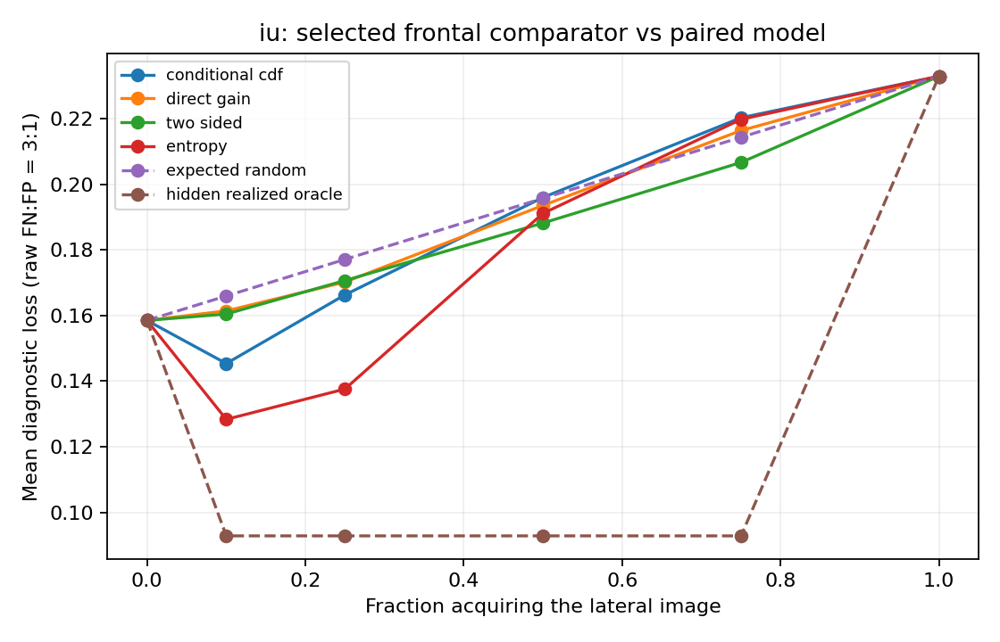
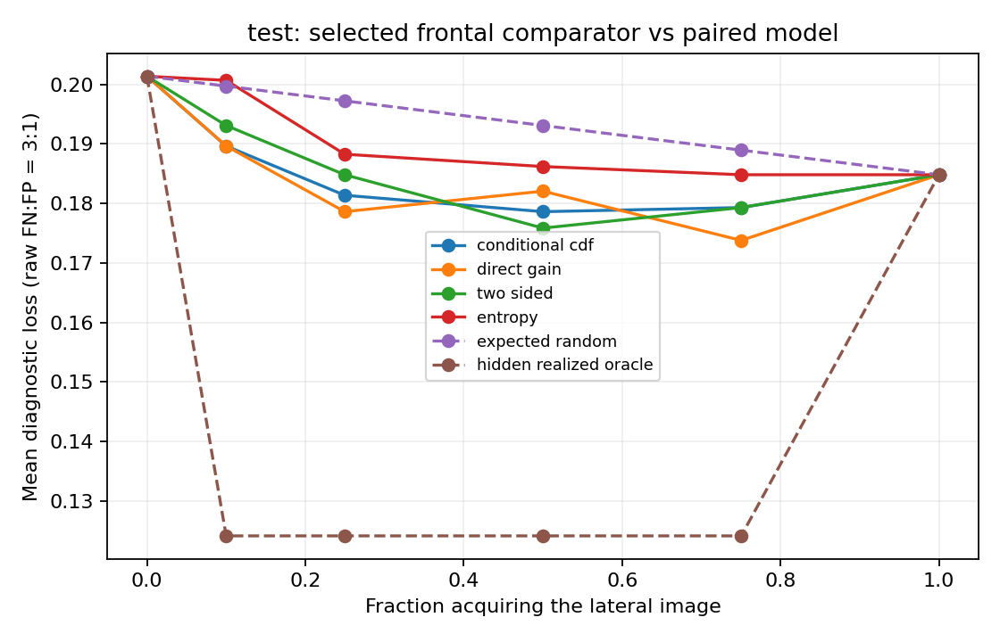
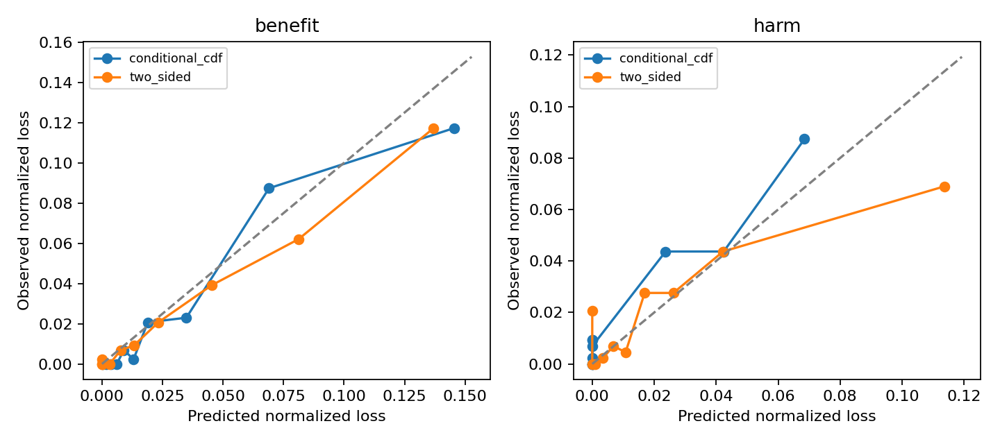
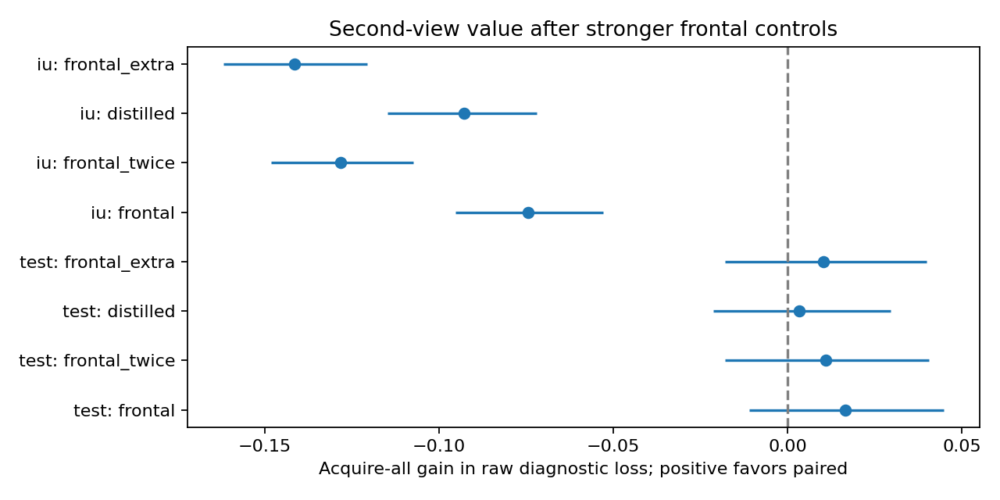

In [6]:
from IPython.display import display, HTML, FileLink, Markdown
import html as html_module
run_dir = Path(RESULT['run_dir'])
archive = Path(RESULT['archive'])
display(Markdown('**COMPLETE**' if RESULT['complete'] else '**PAUSED — retain full Output and resume.**'))
display(FileLink(str(archive)))
if archive.stat().st_size <= 20 * 1024 * 1024:
    payload = base64.b64encode(archive.read_bytes()).decode()
    display(HTML(f'<a download="{html_module.escape(archive.name)}" href="data:application/zip;base64,{payload}">Download results ZIP embedded in this notebook</a>'))
else:
    print('ZIP is too large to embed; download it from Kaggle Output.')
report = run_dir / 'complete_results_report.html'
if RESULT['complete'] and report.exists():
    display(FileLink(str(report)))
    display(HTML(report.read_text()))
else:
    print((run_dir / 'run_status.json').read_text())
